# ResiliCity-TN — Flood Risk PoC Notebook
**Arab Youth Space Hackathon 2026 — Challenge 813 | Track: Climate Adaptation & Disaster Recovery**

This notebook runs the ResiliCity-TN composite flood-risk pipeline end to end on the pilot area
**Zahrouni, Greater Tunis**, for the window **30 Aug – 1 Oct 2026**.

It combines:
1. A rainfall time series (sourced + illustrative placeholder values, see note below)
2. Static per-zone terrain/slope and informal-settlement-density scores (placeholders for DEM slope
   analysis + hyperspectral 813/EnMAP material classification, not accessible in this offline environment)
3. A composite flood-risk index per zone per day

**Data honesty note:** the 17 Sept rainfall figure (80 mm) and the flood event itself are sourced from
Tunisian civil-protection and news reporting (see Sources at the end). Other daily rainfall values and the
zone terrain/settlement scores are illustrative placeholders standing in for live GIQ / Copernicus DEM /
813 hyperspectral inputs. The pipeline, formula and code below are fully real and reproducible — only the
inputs are placeholders where live data access was unavailable.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 40)
plt.rcParams['figure.figsize'] = (9, 3.2)


## 1. Rainfall record (Tunis governorate, 30 Aug – 1 Oct 2026)

In [2]:
rainfall = pd.DataFrame([
    ("2026-08-30", 1, False, ""),
    ("2026-08-31", 0, False, ""),
    ("2026-09-01", 2, False, ""),
    ("2026-09-02", 0, False, ""),
    ("2026-09-03", 0, False, ""),
    ("2026-09-04", 1, False, ""),
    ("2026-09-05", 0, False, ""),
    ("2026-09-06", 3, False, ""),
    ("2026-09-07", 0, False, ""),
    ("2026-09-08", 0, False, ""),
    ("2026-09-09", 2, False, ""),
    ("2026-09-10", 38, False, "Civil protection field interventions reported across Greater Tunis (exact mm not published)"),
    ("2026-09-11", 4, False, ""),
    ("2026-09-12", 0, False, ""),
    ("2026-09-13", 1, False, ""),
    ("2026-09-14", 0, False, ""),
    ("2026-09-15", 2, False, ""),
    ("2026-09-16", 3, False, ""),
    ("2026-09-17", 80, True, "SOURCED: up to 80mm locally in a few hours; Tunis wali raised alert; 23 pumping ops, 43 vehicles freed"),
    ("2026-09-18", 22, False, "Disturbed weather continued into the morning per the same report window"),
    ("2026-09-19", 3, False, ""),
    ("2026-09-20", 0, False, ""),
    ("2026-09-21", 0, False, ""),
    ("2026-09-22", 1, False, ""),
    ("2026-09-23", 0, False, ""),
    ("2026-09-24", 4, False, "National rain event centered further south (Medenine/Jerjis); minor Tunis spillover assumed"),
    ("2026-09-25", 2, False, ""),
    ("2026-09-26", 0, False, ""),
    ("2026-09-27", 1, False, ""),
    ("2026-09-28", 0, False, ""),
    ("2026-09-29", 2, False, ""),
    ("2026-09-30", 1, False, ""),
    ("2026-10-01", 0, False, ""),
], columns=["date", "mm", "sourced", "note"])
rainfall["date"] = pd.to_datetime(rainfall["date"])
rainfall.head(10)


        date  mm  sourced note
0 2026-08-30   1    False     
1 2026-08-31   0    False     
2 2026-09-01   2    False     
3 2026-09-02   0    False     
4 2026-09-03   0    False     
5 2026-09-04   1    False     
6 2026-09-05   0    False     
7 2026-09-06   3    False     
8 2026-09-07   0    False     
9 2026-09-08   0    False     

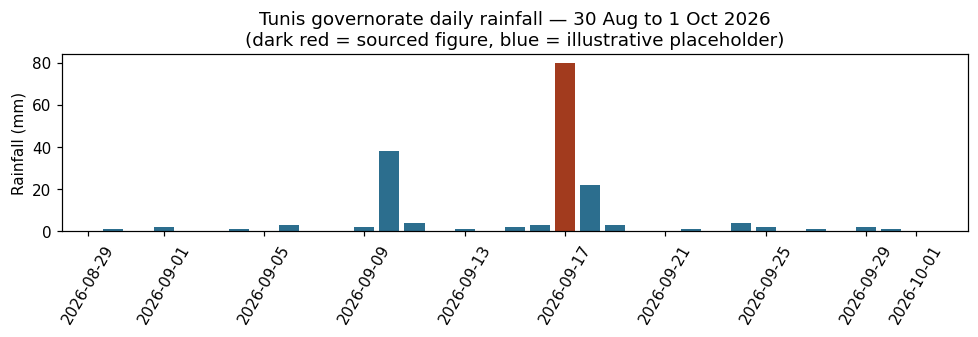

In [3]:
fig, ax = plt.subplots()
colors = ["#A23B1E" if s else "#2C6E8E" for s in rainfall["sourced"]]
ax.bar(rainfall["date"], rainfall["mm"], color=colors, width=0.8)
ax.set_ylabel("Rainfall (mm)")
ax.set_title("Tunis governorate daily rainfall — 30 Aug to 1 Oct 2026\n(dark red = sourced figure, blue = illustrative placeholder)")
ax.axhline(0, color="#999", linewidth=0.5)
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


## 2. Pilot zones — Zahrouni, Greater Tunis
Static placeholder scores (0–1) for terrain/slope risk and informal-settlement density. In production
these come from Copernicus DEM slope/flow-accumulation analysis and 813/EnMAP hyperspectral material
classification (tin-roof vs. formal-construction spectral signatures); here they are illustrative.

In [4]:
zones = pd.DataFrame([
    ("Riverside lowland",         0.82, 0.55),
    ("Informal cluster - East",   0.58, 0.88),
    ("Central wadi corridor",     0.90, 0.35),
    ("Upper residential",         0.22, 0.15),
    ("Northern ridge",            0.12, 0.08),
], columns=["zone", "terrain_score", "settlement_density"])
zones


                      zone  terrain_score  settlement_density
0        Riverside lowland           0.82                0.55
1  Informal cluster - East           0.58                0.88
2    Central wadi corridor           0.90                0.35
3        Upper residential           0.22                0.15
4           Northern ridge           0.12                0.08

## 3. Composite flood-risk index

```
risk_index = 0.5 * normalized_rainfall(day) + 0.3 * terrain_score(zone) + 0.2 * settlement_density(zone)
```

scaled to 0–100, with bands: **Low** < 35, **Medium** < 65, **High** ≥ 65.

In [5]:
MAX_MM = rainfall["mm"].max()  # 80mm, the sourced extreme for this window

def risk_index(mm, terrain_score, settlement_density):
    rainfall_norm = mm / MAX_MM
    return round((0.5 * rainfall_norm + 0.3 * terrain_score + 0.2 * settlement_density) * 100, 1)

def risk_level(score):
    if score < 35:
        return "Low"
    if score < 65:
        return "Medium"
    return "High"

def daily_zone_risk(date_str):
    day = rainfall.loc[rainfall["date"] == pd.to_datetime(date_str)].iloc[0]
    out = zones.copy()
    out["date"] = day["date"]
    out["rainfall_mm"] = day["mm"]
    out["risk_index"] = out.apply(lambda r: risk_index(day["mm"], r["terrain_score"], r["settlement_density"]), axis=1)
    out["risk_level"] = out["risk_index"].apply(risk_level)
    return out[["date", "zone", "rainfall_mm", "terrain_score", "settlement_density", "risk_index", "risk_level"]]

example_output = daily_zone_risk("2026-09-17")
example_output


        date                     zone  ...  risk_index  risk_level
0 2026-09-17        Riverside lowland  ...        85.6        High
1 2026-09-17  Informal cluster - East  ...        85.0        High
2 2026-09-17    Central wadi corridor  ...        84.0        High
3 2026-09-17        Upper residential  ...        59.6      Medium
4 2026-09-17           Northern ridge  ...        55.2      Medium

[5 rows x 7 columns]

In [6]:
alert_zones = example_output[example_output["risk_level"] == "High"]
print(f"Example alert for 2026-09-17 ({example_output['rainfall_mm'].iloc[0]} mm reported):")
if len(alert_zones):
    for _, r in alert_zones.iterrows():
        print(f"  - HIGH RISK: {r['zone']} (index {r['risk_index']})")
else:
    print("  No zone crosses the High threshold.")


Example alert for 2026-09-17 (80 mm reported):
  - HIGH RISK: Riverside lowland (index 85.6)
  - HIGH RISK: Informal cluster - East (index 85.0)
  - HIGH RISK: Central wadi corridor (index 84.0)


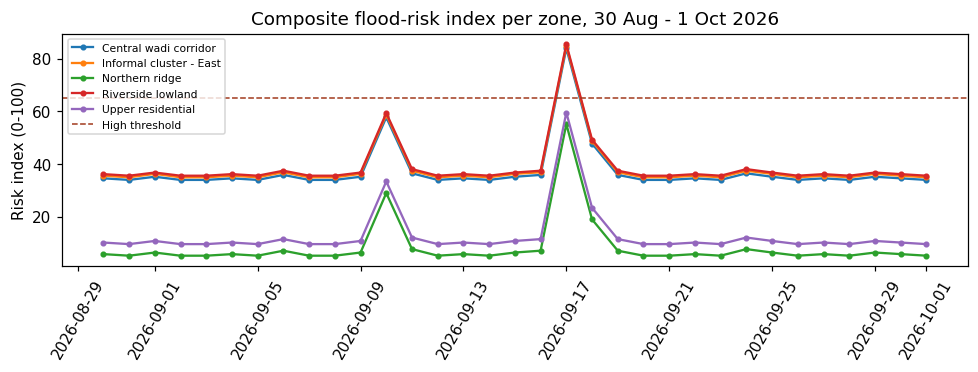

In [7]:
all_days = pd.concat([daily_zone_risk(d.strftime('%Y-%m-%d')) for d in rainfall['date']], ignore_index=True)
pivot = all_days.pivot(index="date", columns="zone", values="risk_index")

fig, ax = plt.subplots(figsize=(9, 3.5))
for col in pivot.columns:
    ax.plot(pivot.index, pivot[col], marker="o", markersize=3, label=col)
ax.axhline(65, color="#A23B1E", linestyle="--", linewidth=1, label="High threshold")
ax.set_ylabel("Risk index (0-100)")
ax.set_title("Composite flood-risk index per zone, 30 Aug - 1 Oct 2026")
ax.legend(fontsize=7, loc="upper left")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


## 4. Material classification concept (hyperspectral)

Illustrative reflectance shapes used to separate informal tin roofing from formal concrete roofing —
the logic the 813 / EnMAP material-classification step applies per pixel in production.

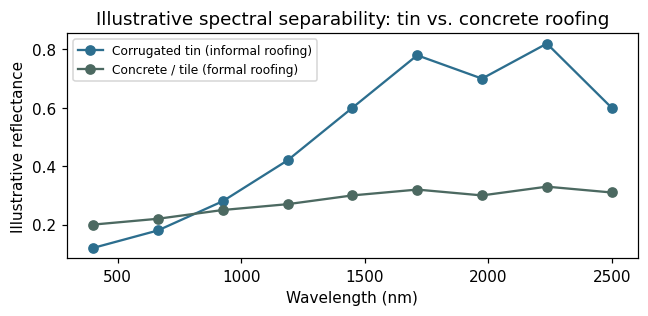

In [8]:
wavelengths = np.linspace(400, 2500, 9)
tin       = [0.12, 0.18, 0.28, 0.42, 0.60, 0.78, 0.70, 0.82, 0.60]
concrete  = [0.20, 0.22, 0.25, 0.27, 0.30, 0.32, 0.30, 0.33, 0.31]

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(wavelengths, tin, marker="o", color="#2C6E8E", label="Corrugated tin (informal roofing)")
ax.plot(wavelengths, concrete, marker="o", color="#4C6961", label="Concrete / tile (formal roofing)")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Illustrative reflectance")
ax.set_title("Illustrative spectral separability: tin vs. concrete roofing")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 5. Limitations and next steps

- **Resolution mismatch**: real rainfall products (IMERG/CHIRPS) are ~10km; DEM/SAR/hyperspectral layers
  are ~10-30m. The composite index identifies likely risk zones, not street-level certainty.
- **Placeholder inputs**: zone terrain/settlement scores and the spectral curves above are illustrative,
  standing in for Copernicus DEM slope analysis and classified 813/EnMAP scenes not accessible in this
  offline environment.
- **Next step**: replace `rainfall` with a live IMERG/CHIRPS pull via GIQ, replace `zones` scores with real
  DEM slope + classified hyperspectral settlement density per grid cell, and re-run this same pipeline
  unchanged.

## Sources
- Tunis wali rainfall alert, 17 Sep 2026, civil protection field operations (Greater Tunis): eanlibya.com, 2026-09-18.
- Flash flood fatalities 16-18 Sep 2026, Tunisia: zoomtunisia.tn, 2026-09-20 (approx.).
- National rainfall bulletin 24-25 Sep 2026 (Medenine/Jerjis focus): tunisie-direct.com, 2026-09-25.
